In [ ]:
import sys, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, pairwise_distances)

import warnings; warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Ready.")

Ready.


In [ ]:
if "google.colab" in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    FILENAME = list(uploaded.keys())[0]

print("Using file:", FILENAME)

Saving FTSE 250 2021–2026 Dataset.csv to FTSE 250 2021–2026 Dataset (1).csv
Using file: FTSE 250 2021–2026 Dataset (1).csv


In [ ]:
MAX_MISSING_FRAC = 0.10

df = pd.read_csv(FILENAME)
date_cols = [c for c in df.columns if c != "Ticker"]

frac = df[date_cols].isna().sum(axis=1) / len(date_cols)
dropped = df.loc[frac > MAX_MISSING_FRAC, "Ticker"].tolist()
df = df.loc[frac <= MAX_MISSING_FRAC].reset_index(drop=True)

n_filled = int(df[date_cols].isna().sum().sum())
df[date_cols] = df[date_cols].ffill(axis=1).bfill(axis=1)

tickers = df["Ticker"].values
A = df[date_cols].values.astype(float)
dates = pd.to_datetime(date_cols)

print(f"Dropped (>10% missing) : {len(dropped)} {dropped}")
print(f"Single gaps filled     : {n_filled}")
print(f"Stocks retained        : {len(df)}")
print(f"Trading days           : {len(date_cols)}")
print(f"Date range             : {date_cols[0]} to {date_cols[-1]}")
assert df[date_cols].isna().sum().sum() == 0

Dropped (>10% missing) : 0 []
Single gaps filled     : 4
Stocks retained        : 241
Trading days           : 1153
Date range             : 2021-11-30 to 2026-06-29


In [ ]:
USE_PCA = True
VARIANCE_TARGET = 0.90

if USE_PCA:
    pca = PCA(n_components=VARIANCE_TARGET, random_state=RANDOM_STATE)
    X = pca.fit_transform(A)
    print(f"PCA: {A.shape[1]} days -> {X.shape[1]} components "
          f"({VARIANCE_TARGET:.0%} of variance)")
    print(f"PC1 alone explains {pca.explained_variance_ratio_[0]*100:.1f}% "
          f"(this is the common market factor)")
else:
    X = A
    print(f"No PCA: clustering raw {X.shape[1]} dimensions")

print("Clustering matrix:", X.shape)

PCA: 1153 days -> 9 components (90% of variance)
PC1 alone explains 48.0% (this is the common market factor)
Clustering matrix: (241, 9)


In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

K_RANGE = range(2, 11)
N_SUBSAMPLES = 100
SUBSAMPLE_FRAC = 0.8


_CM_CACHE = {}


def consensus_matrix(X, k, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC,
                     n_init=5, seed=RANDOM_STATE):

    key = (id(X), X.shape, k, B, frac, n_init, seed)
    if key in _CM_CACHE:
        return _CM_CACHE[key]

    rng = np.random.default_rng(seed)
    n = X.shape[0]
    m = int(frac * n)

    together = np.zeros((n, n))
    sampled = np.zeros((n, n))
    for b in range(B):
        idx = rng.choice(n, m, replace=False)
        lab = KMeans(k, n_init=n_init, random_state=seed + b).fit_predict(X[idx])
        ix = np.ix_(idx, idx)
        together[ix] += (lab[:, None] == lab[None, :])
        sampled[ix] += 1


    M = np.divide(together, sampled, out=np.zeros((n, n)), where=sampled > 0)
    np.fill_diagonal(M, 1.0)
    _CM_CACHE[key] = M
    return M


def cluster_consensus(M, labels):

    out = []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        if len(idx) < 2:
            out.append(np.nan)
            continue
        sub = M[np.ix_(idx, idx)]
        out.append(sub[np.triu_indices(len(idx), 1)].mean())
    return np.array(out)


def subsample_stability(X, k, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC,
                        n_init=5, seed=RANDOM_STATE):

    M = consensus_matrix(X, k, B=B, frac=frac, n_init=n_init, seed=seed)
    labels = KMeans(k, n_init=10, random_state=seed).fit_predict(X)
    mk = cluster_consensus(M, labels)
    if np.all(np.isnan(mk)):
        return np.nan, np.nan
    return float(np.nanmean(mk)), float(np.nanmin(mk))


def dunn_index(X, labels):

    labels = np.asarray(labels)
    D = pairwise_distances(X)
    same = labels[:, None] == labels[None, :]
    max_diameter = D[same].max()
    min_separation = D[~same].min()
    return float(min_separation / max_diameter) if max_diameter > 0 else np.nan


print("Functions defined.")

Functions defined.


In [ ]:
t0 = time.time()
n = len(X)
rows = []
cc_by_k = {}
for k in K_RANGE:
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    stab, stab_min = subsample_stability(X, k)
    cc_by_k[k] = cluster_consensus(consensus_matrix(X, k), lab)
    smallest = int(np.bincount(lab, minlength=k).min())
    rows.append({
        "k": k,
        "silhouette": silhouette_score(X, lab, sample_size=min(n, 5000),
                                       random_state=RANDOM_STATE),
        "calinski": calinski_harabasz_score(X, lab),
        "davies_bouldin": davies_bouldin_score(X, lab),
        "dunn": dunn_index(X, lab),
        "stability": stab,
        "stability_min": stab_min,
        "smallest_cluster": smallest,
        "smallest_pct": 100 * smallest / n,
    })

metrics = pd.DataFrame(rows)

print(f"Computed in {time.time()-t0:.0f}s")
print(f"Dunn index alone picks k = {int(metrics.loc[metrics['dunn'].idxmax(), 'k'])}\n")
display(metrics.round(4))

cols = [f"Cluster {c + 1}" for c in range(max(K_RANGE))]
cluster_consensus_table = pd.DataFrame(
    [list(v) + [np.nan] * (len(cols) - len(v)) for v in cc_by_k.values()],
    index=list(cc_by_k), columns=cols)
cluster_consensus_table = cluster_consensus_table.rename_axis(index=None, columns="k")

print("\nCluster consensus per candidate k (1 = perfectly stable; blank = k has no such cluster)")
display(cluster_consensus_table.style.format("{:.3f}", na_rep="")
        .background_gradient(cmap="Reds", vmin=0, vmax=1))

Computed in 13s
Dunn index alone picks k = 2



,k,silhouette,calinski,davies_bouldin,dunn,stability,stability_min,smallest_cluster,smallest_pct
0,2,0.3745,175.2400,1.1184,0.1686,0.9864,0.9804,111,46.0581
1,3,0.2854,126.5068,1.3995,0.1351,0.7290,0.6281,56,23.2365
2,4,0.2888,115.6018,1.2893,0.1323,0.8710,0.7904,46,19.0871
3,5,0.2344,103.3873,1.3812,0.1149,0.8652,0.8436,34,14.1079
4,6,0.2423,94.2368,1.4098,0.1369,0.7997,0.7129,23,9.5436
5,7,0.2071,85.6944,1.4261,0.1336,0.6905,0.6360,21,8.7137
6,8,0.1828,78.4358,1.4616,0.1063,0.6932,0.5375,18,7.4689
7,9,0.1863,73.6242,1.4925,0.1127,0.6441,0.5340,11,4.5643
8,10,0.1759,69.6627,1.4413,0.1182,0.6065,0.5101,10,4.1494



Cluster consensus per candidate k (1 = perfectly stable; blank = k has no such cluster)


k,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9,Cluster 10
2,0.992,0.980,,,,,,,,
3,0.628,0.814,0.745,,,,,,,
4,0.860,0.864,0.790,0.970,,,,,,
5,0.876,0.846,0.889,0.844,0.871,,,,,
6,0.713,0.825,0.783,0.778,0.886,0.813,,,,
7,0.644,0.802,0.689,0.677,0.717,0.668,0.636,,,
8,0.656,0.537,0.664,0.860,0.656,0.732,0.706,0.734,,
9,0.730,0.673,0.688,0.697,0.534,0.559,0.734,0.604,0.579,
10,0.662,0.517,0.510,0.591,0.676,0.703,0.688,0.660,0.516,0.540


In [ ]:
RANK_METRICS = {
    "silhouette": False,
    "calinski": False,
    "davies_bouldin": True,
    "dunn": False,
}

ranked = metrics.copy()
for col, lower_is_better in RANK_METRICS.items():
    ranked[f"r_{col}"] = ranked[col].rank(ascending=lower_is_better)
ranked["mean_rank"] = ranked[[f"r_{c}" for c in RANK_METRICS]].mean(axis=1)


best = ranked.sort_values(["mean_rank", "k"]).iloc[0]
consensus_k = int(best["k"])


metrics = metrics.drop(columns=[c for c in metrics.columns
                                if c.startswith("r_") or c == "mean_rank"])
metrics = metrics.join(ranked[[f"r_{c}" for c in RANK_METRICS] + ["mean_rank"]])

print(f"Silhouette alone would pick k = {int(metrics.loc[metrics['silhouette'].idxmax(), 'k'])}")
print(f"Dunn index alone would pick k = {int(metrics.loc[metrics['dunn'].idxmax(), 'k'])}")
print(f"Consensus of {len(RANK_METRICS)} metrics   k = {consensus_k}")
print(f"\nMean cluster consensus at consensus k : {best['stability']:.3f}")
print(f"Smallest cluster at consensus k       : {int(best['smallest_cluster'])} "
      f"({best['smallest_pct']:.1f}%)")

Silhouette alone would pick k = 2
Dunn index alone would pick k = 2
Consensus of 4 metrics   k = 2

Mean cluster consensus at consensus k : 0.986
Smallest cluster at consensus k       : 111 (46.1%)


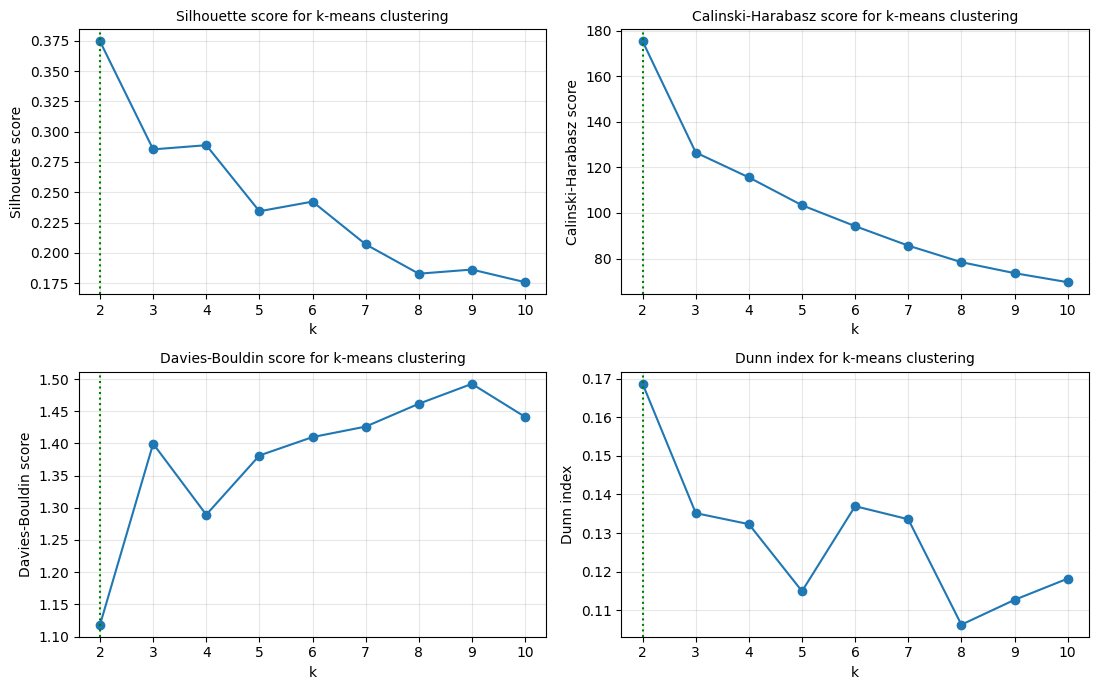

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

specs = [("silhouette", "Silhouette score"),
         ("calinski", "Calinski-Harabasz score"),
         ("davies_bouldin", "Davies-Bouldin score"),
         ("dunn", "Dunn index")]

ks = metrics["k"]

for ax, (col, name) in zip(axes.flat, specs):
    ax.plot(ks, metrics[col], marker="o", color="C0")
    ax.axvline(consensus_k, color="green", ls=":", lw=1.5)
    ax.set_title(f"{name} for k-means clustering", fontsize=10)
    ax.set_xlabel("k")
    ax.set_ylabel(name)
    ax.set_xticks(ks)

plt.tight_layout()
plt.show()

In [ ]:
FINAL_K = consensus_k

assert len(tickers) == X.shape[0], "tickers and X are misaligned"

labels = KMeans(FINAL_K, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
stab, stab_min = subsample_stability(X, FINAL_K)
sizes = np.bincount(labels, minlength=FINAL_K)

print("=" * 46)
print(f"  DATASET     : {FILENAME}")
print(f"  Stocks      : {len(tickers)}")
print(f"  Dimensions  : {X.shape[1]}" + ("  (PCA)" if USE_PCA else "  (raw)"))
print(f"  k           : {FINAL_K}")
print("-" * 46)
print(f"  Silhouette     : {silhouette_score(X, labels):.4f}")
print(f"  Calinski-H     : {calinski_harabasz_score(X, labels):.1f}")
print(f"  Davies-Bouldin : {davies_bouldin_score(X, labels):.4f}")
print(f"  Dunn index     : {dunn_index(X, labels):.4f}")
print(f"  Cluster consensus (mean) : {stab:.4f}  (least stable cluster {stab_min:.3f})")
print("-" * 46)
print(f"  Cluster sizes  : {sizes.tolist()}")
print(f"  Sizes (%)      : {[round(100 * s / len(labels), 1) for s in sizes]}")
print("=" * 46)


assignments = pd.DataFrame({"ticker": list(tickers), "cluster": labels})

  DATASET     : FTSE 250 2021–2026 Dataset (1).csv
  Stocks      : 241
  Dimensions  : 9  (PCA)
  k           : 2
----------------------------------------------
  Silhouette     : 0.3745
  Calinski-H     : 175.2
  Davies-Bouldin : 1.1184
  Dunn index     : 0.1686
  Cluster consensus (mean) : 0.9864  (least stable cluster 0.980)
----------------------------------------------
  Cluster sizes  : [130, 111]
  Sizes (%)      : [np.float64(53.9), np.float64(46.1)]


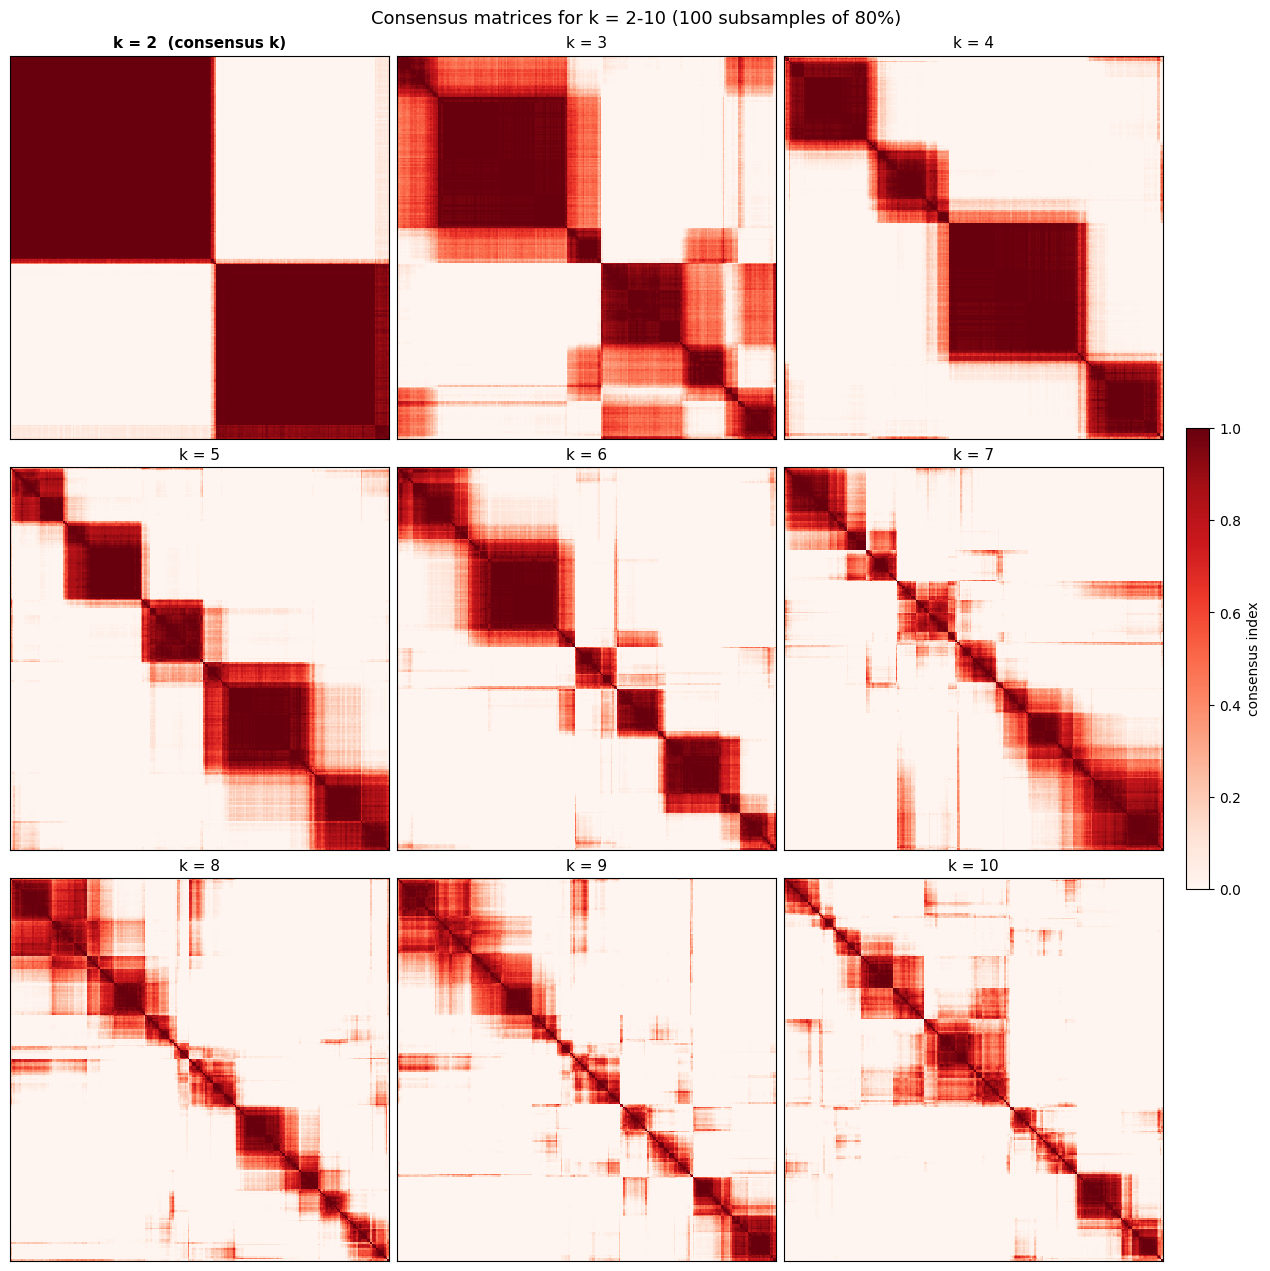

In [ ]:
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform

ks_all = list(K_RANGE)
ncols = 3
nrows = int(np.ceil(len(ks_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), squeeze=False,
                         constrained_layout=True)

for ax, k in zip(axes.flat, ks_all):
    Mk = consensus_matrix(X, k)
    Dk = squareform(1 - Mk, checks=False)
    order_k = leaves_list(optimal_leaf_ordering(linkage(Dk, method="average"), Dk))
    im = ax.imshow(Mk[np.ix_(order_k, order_k)], cmap="Reds", vmin=0, vmax=1,
                   interpolation="nearest", aspect="auto")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"k = {k}" + ("  (consensus k)" if k == FINAL_K else ""),
                 fontsize=11, fontweight="bold" if k == FINAL_K else "normal")
for ax in axes.flat[len(ks_all):]:
    ax.axis("off")

fig.suptitle(f"Consensus matrices for k = {ks_all[0]}-{ks_all[-1]} "
             f"({N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%})", fontsize=13)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="consensus index")
plt.show()


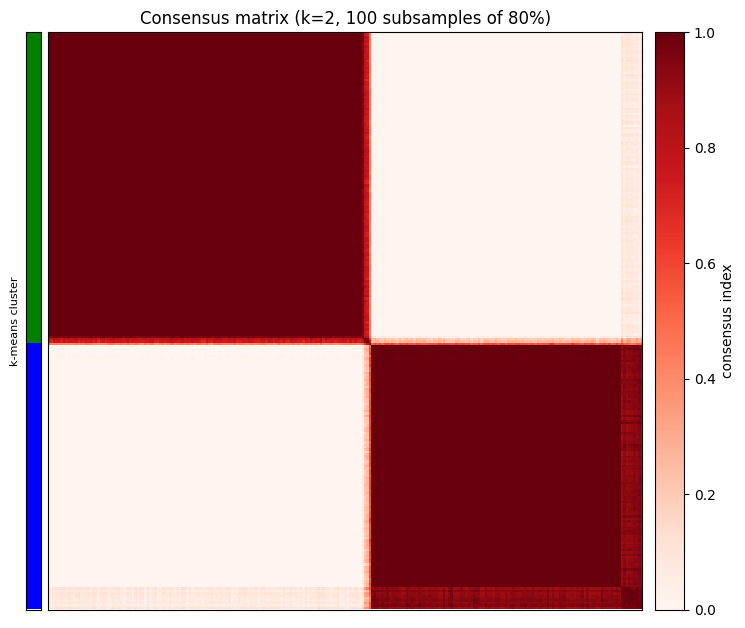

Cluster consensus m(k)  (1 = perfectly stable):
  Cluster 0 (n=130): 0.992
  Cluster 1 (n=111): 0.980


In [ ]:
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap

M = consensus_matrix(X, FINAL_K)

D = squareform(1 - M, checks=False)
order = leaves_list(optimal_leaf_ordering(linkage(D, method="average"), D))

side_colors = ListedColormap(["green", "blue", "orange", "red", "purple",
                              "brown", "pink", "grey", "olive", "cyan"][:FINAL_K])

fig, (ax_bar, ax_hm) = plt.subplots(1, 2, figsize=(8.5, 7.5),
                                    gridspec_kw={"width_ratios": [1, 40], "wspace": 0.02})
im = ax_hm.imshow(M[np.ix_(order, order)], cmap="Reds", vmin=0, vmax=1,
                  interpolation="nearest", aspect="auto")
ax_bar.imshow(labels[order][:, None], cmap=side_colors, vmin=0, vmax=max(FINAL_K - 1, 1),
              interpolation="nearest", aspect="auto")
for ax in (ax_bar, ax_hm):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax_bar.set_ylabel("k-means cluster", fontsize=8)
ax_hm.set_title(f"Consensus matrix (k={FINAL_K}, {N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%})")
fig.colorbar(im, ax=ax_hm, fraction=0.046, pad=0.02, label="consensus index")
plt.show()

mk = cluster_consensus(M, labels)
print("Cluster consensus m(k)  (1 = perfectly stable):")
for c in range(FINAL_K):
    print(f"  Cluster {c} (n={int((labels == c).sum())}): {mk[c]:.3f}")


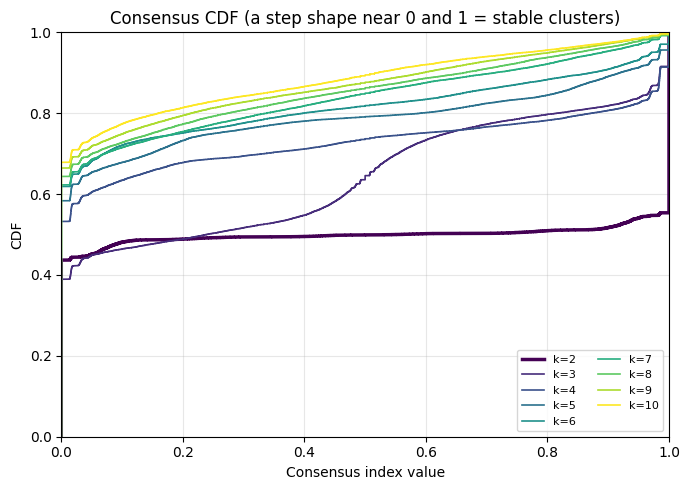

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = plt.get_cmap("viridis", len(K_RANGE))

for i, k in enumerate(K_RANGE):
    Mk = consensus_matrix(X, k)
    vals = np.sort(Mk[np.triu_indices(Mk.shape[0], 1)])
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, cdf, where="post", color=colors(i),
            lw=2.5 if k == FINAL_K else 1.2, label=f"k={k}")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Consensus index value")
ax.set_ylabel("CDF")
ax.set_title("Consensus CDF (a step shape near 0 and 1 = stable clusters)")
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

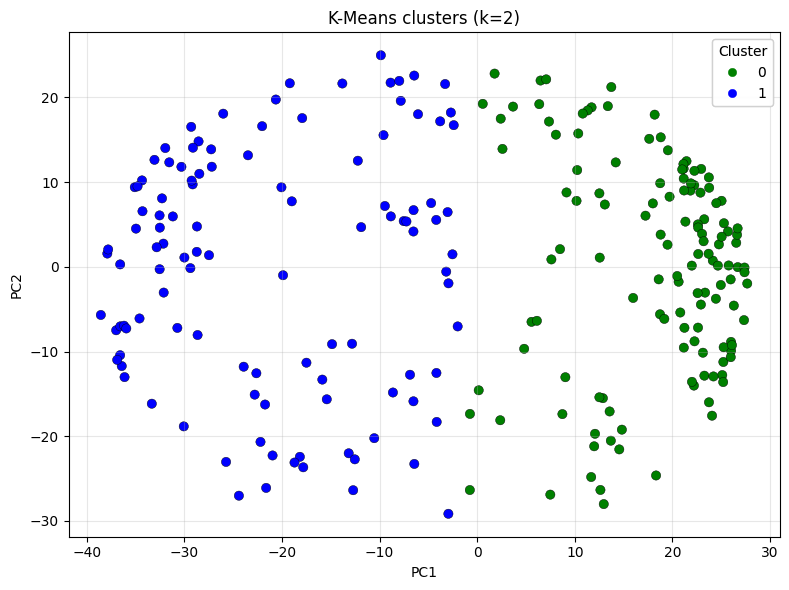

In [ ]:
from matplotlib.colors import ListedColormap

vis = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
V = vis.transform(X)

cmap = ListedColormap(["green", "blue", "orange", "red", "purple", "brown", "pink", "grey", "olive", "cyan"][:FINAL_K])

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(V[:, 0], V[:, 1], c=labels, cmap=cmap, s=45, edgecolor="k", linewidth=0.3)
ax.set_title(f"K-Means clusters (k={FINAL_K})")
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.add_artist(ax.legend(*sc.legend_elements(), title="Cluster", loc="best"))
plt.tight_layout(); plt.show()

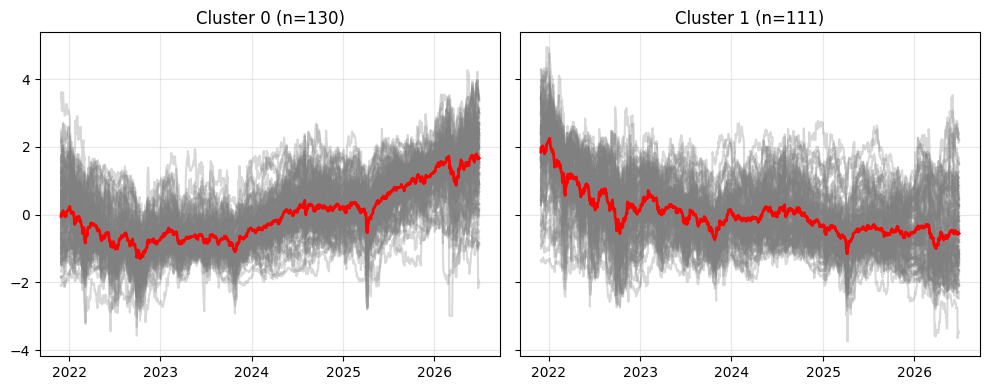

In [ ]:
fig, axes = plt.subplots(1, FINAL_K, figsize=(5 * FINAL_K, 4), sharey=True, squeeze=False)
axes = axes[0]

for c in range(FINAL_K):
    ax = axes[c]
    mem = A[labels == c]


    ax.plot(dates, mem.T, alpha=0.3, color="gray")


    ax.plot(dates, mem.mean(axis=0), color="red", linewidth=2)

    ax.set_title(f"Cluster {c} (n={len(mem)})")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [ ]:
import textwrap
for c in range(FINAL_K):
    mem = sorted(tickers[labels == c])
    print(f"Cluster {c} (n={len(mem)}):")
    print(textwrap.fill(", ".join(mem), width=95))
    print()

Cluster 0 (n=130):
3IN.L, AAS.L, AEP.L, AGT.L, AIE.L, AJB.L, ALFA.L, AO.L, ASL.L, ATR.L, ATT.L, ATYM.L, AVON.L,
BAG.L, BBY.L, BCG.L, BGFD.L, BMY.L, BNKR.L, BOWL.L, BPCR.L, BRGE.L, BRWM.L, BUT.L, CHG.L,
CKN.L, CLDN.L, CMCX.L, COA.L, CORD.L, COST.L, CSN.L, CTY.L, CURY.L, CWK.L, DRX.L, EDIN.L,
ELM.L, ESCT.L, EWG.L, EWI.L, FAN.L, FCH.L, FCSS.L, FEML.L, FEV.L, FGP.L, FSG.L, FSV.L, GDWN.L,
GFRD.L, GNC.L, GSCT.L, HANA.L, HGT.L, HILS.L, HMSO.L, HOC.L, HRI.L, HTG.L, HTWS.L, HVPE.L,
HWG.L, IAD.L, ICGT.L, IPF.L, JAM.L, JCH.L, JEDT.L, JEGI.L, JEMI.L, JFJ.L, JGGI.L, JMGI.L,
JSG.L, JTC.L, KIE.L, KLR.L, LRE.L, LWDB.L, MAB.L, MEGP.L, MGNS.L, MNKS.L, MRC.L, MRCH.L, MTO.L,
MTRO.L, MUT.L, MYI.L, OCI.L, OSB.L, PAF.L, PAG.L, PCGH.L, PEY.L, PFD.L, PHI.L, PIN.L, PINT.L,
PLUS.L, PNL.L, POLN.L, PPET.L, PPH.L, QLT.L, QQ.L, RHIM.L, ROR.L, RTW.L, SAGA.L, SAIN.L, SCT.L,
SDP.L, SNR.L, SOI.L, SRP.L, TBCG.L, TCAP.L, TEM.L, TFIF.L, TMPL.L, TRST.L, UEM.L, USA.L,
VEIL.L, VSVS.L, WIX.L, WWH.L, XPS.L

Cluster 1 (n=111):
A